# 第 1 堂：把西洋棋殘局變成程式

今天要做的事：

1. 認識西洋棋的基本規則，先自己玩玩看
2. 學會用 Colab 寫程式
3. 寫一個「棋盤程式」，讓電腦可以在裡面下王車殺單王
4. 讓電腦亂下 3000 盤，看看亂下能贏幾盤
5. 把今天的成果存到 GitHub

有 `# TODO` 的地方是要你自己寫的。寫完記得執行下面那一格檢查。

## 先玩再寫：西洋棋規則

這門課只會用到三個棋子：白方的王和車，黑方的王。

- **王**：往旁邊八格的任何一格走一步。
- **車**：直的或橫的走，幾格都可以，但不能跳過其他棋子。跟象棋的車一樣。
- 走到對方棋子的格子上，就是把它吃掉。

三個一定要懂的詞：

- **將軍**：你的王正在被攻擊，下一步就會被吃。被將軍一定要逃掉。
- **將死**：被將軍，而且怎麼走都逃不掉。將死的人輸了。
- **逼和**：輪到你走，你的王**沒有**被將軍，但是一步都走不了。這時算和局，明明快贏的一方也贏不了。

另外：兩個王永遠不能貼在一起，因為那等於自己走到對方王的攻擊範圍。

**先試試看**：打開 [lichess 棋盤編輯器](https://lichess.org/editor)，擺一個白王、一個白車、一個黑王，按「從這裡繼續 → 與電腦對弈」（英文介面是 Continue from here → Play with the computer），你拿白棋，試著把黑王將死。注意兩件事：你的車有沒有被吃掉？有沒有不小心變成逼和？等一下電腦亂下的時候，也會一直犯這兩個錯。

## 0. Colab 怎麼用

- 灰色的格子是程式。點一下，按 **Shift + Enter** 就會執行，然後跳到下一格。
- 白色的格子是說明文字，不用執行。
- 程式要從上往下執行。如果中間關掉重開，上面的格子要重新跑一次（上方選單「執行階段 → 全部執行」）。
- 格子左邊出現數字，代表這格跑過了。數字是執行的順序。

先試試看：

In [ ]:
print("Colab 可以用了")

Colab 可以用了


## 1. 安裝西洋棋套件

Python 本身不會下棋。我們借用別人寫好的套件 `python-chess`，它會幫我們處理棋規：哪些走法合法、有沒有將軍、是不是將死。

我們這門課的重點不是寫棋規，是讓電腦**學會下**。所以棋規就交給套件。

In [ ]:
!pip install -q chess

import chess
import random

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 52.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 2. 認識棋盤

建立一個標準開局的棋盤。最後一行只寫變數名稱，Colab 就會把棋盤畫出來。

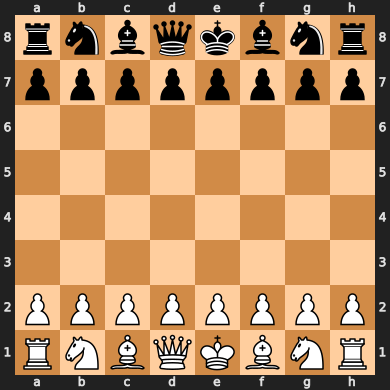

In [ ]:
board = chess.Board()
board

棋盤的直行是 a 到 h，橫列是 1 到 8，左下角是 a1。

在程式裡，每一格其實是一個 0 到 63 的數字：a1 是 0，b1 是 1，一直到 h8 是 63。

In [ ]:
print(chess.A1, chess.H1, chess.A8, chess.H8)
print(chess.square_name(28))   # 28 號格是哪一格？

0 7 56 63
e4


`board.legal_moves` 會列出現在所有合法的走法。把它變成 list，就可以算有幾個、或是挑一個來走。

In [ ]:
moves = list(board.legal_moves)
print("白方現在有", len(moves), "種走法")
print(moves[:5])

白方現在有 20 種走法
[Move.from_uci('g1h3'), Move.from_uci('g1f3'), Move.from_uci('b1c3'), Move.from_uci('b1a3'), Move.from_uci('h2h3')]


`board.push(走法)` 就是走一步。走完之後輪到黑方。

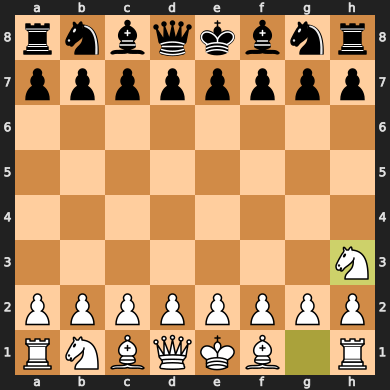

In [ ]:
board.push(moves[0])
board

### 練習 1

讓白方隨機走一步、黑方隨機走一步，重複 5 次，最後把棋盤畫出來。

提示：`random.choice(一個 list)` 會從 list 裡隨機挑一個。

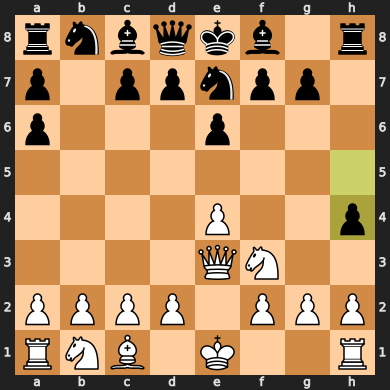

In [ ]:
import random

board = chess.Board()

for i in range(5):
    # 白方隨機走一步
    if not board.is_game_over():
        white_move = random.choice(list(board.legal_moves))
        board.push(white_move)

    # 黑方隨機走一步
    if not board.is_game_over():
        black_move = random.choice(list(board.legal_moves))
        board.push(black_move)

board

## 3. 擺出王車殺單王

`chess.Board(None)` 會給你一個空棋盤，再用 `set_piece_at(格子, 棋子)` 把棋子一個一個放上去。

下面這個就是上次投影片裡那個將死的局面：

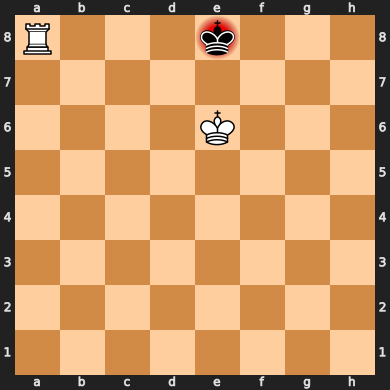

In [ ]:
board = chess.Board(None)
board.set_piece_at(chess.E6, chess.Piece(chess.KING, chess.WHITE))
board.set_piece_at(chess.A8, chess.Piece(chess.ROOK, chess.WHITE))
board.set_piece_at(chess.E8, chess.Piece(chess.KING, chess.BLACK))
board.turn = chess.BLACK   # 輪到黑方

board

In [ ]:
print("黑方被將軍了嗎？", board.is_check())
print("將死了嗎？", board.is_checkmate())

黑方被將軍了嗎？ True
將死了嗎？ True


### 練習 2

寫一個函式 `random_krk_board()`，每次呼叫都會隨機擺出一個王車殺單王的局面，輪到白方走。

要注意兩件事：

- 三個棋子不能放在同一格。`random.sample(chess.SQUARES, 3)` 可以一次抽 3 個**不重複**的格子。
- 有些擺法不合規則，例如兩個王貼在一起，或是輪到白方走時黑王已經被將軍。`board.is_valid()` 會幫我們檢查，不合法就重抽一次。

大部分已經幫你寫好了，你只要補兩行。

In [ ]:
def random_krk_board():
    while True:
        board = chess.Board(None)
        wk, wr, bk = random.sample(chess.SQUARES, 3)   # 白王、白車、黑王的位置

        board.set_piece_at(wk, chess.Piece(chess.KING, chess.WHITE))
        # TODO: 把白車放到 wr
        board.set_piece_at(wr, chess.Piece(chess.ROOK, chess.WHITE))
        board.set_piece_at(bk, chess.Piece(chess.KING, chess.BLACK))

        # TODO: 把黑王放到 bk

        board.turn = chess.WHITE

        if board.is_valid() and not board.is_game_over():
            return board

執行下面這格檢查。多跑幾次，每次的局面應該都不一樣，而且棋盤上都剛好 3 顆棋子。

棋子數量： 3


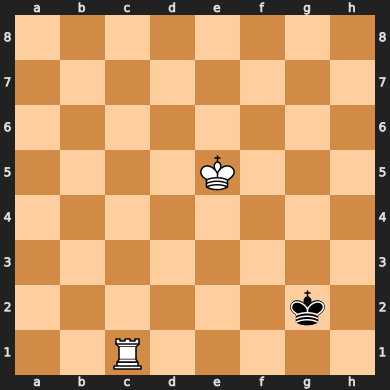

In [ ]:
b = random_krk_board()
print("棋子數量：", len(b.piece_map()))
b

## 4. 棋盤程式（環境）

上次講過，電腦學下棋需要一個「棋盤程式」，它要會做三件事：

| 函式 | 做什麼 |
|---|---|
| `reset()` | 開一盤新棋，回傳開始的局面 |
| `step(走法)` | 白方走一步、黑方回一步，回傳：新的局面、這步拿到的分數、這盤結束了沒 |
| `is_terminal()` | 這盤棋結束了嗎 |

我們用 `class` 把這些包在一起。你可以把 class 想成一個盒子：裡面放著資料（棋盤、已經走了幾步），也放著功能（reset、step）。程式裡的 `self` 指的就是「這個盒子自己」，`self.board` 就是盒子裡的棋盤。

分數規則跟上次投影片一樣：

| 發生什麼事 | 分數 |
|---|---|
| 將死對方 | +1 |
| 逼和 | −1 |
| 車被吃掉 | −1 |
| 每走一步 | −0.01 |

另外兩個設定：

- 黑方先讓它亂走。之後想讓電腦變強，可以再把黑方改聰明。
- 走到 50 步還沒結束，這盤就直接結束。

「局面」我們用三個棋子的位置來表示，例如 `(20, 0, 60)` 代表白王在 20 號格、白車在 0 號格、黑王在 60 號格。車被吃掉的話，車的位置是 `None`。

### 練習 3

下面的 class 大部分寫好了。你要補 `step()` 裡面的兩段：將死和逼和的判斷。

先把整個 class 從上往下讀一次，看懂每一段在做什麼再動手。

In [ ]:
class KRKEnv:
    def __init__(self, max_steps=50):
        self.max_steps = max_steps

    def reset(self):
        self.board = random_krk_board()
        self.steps = 0
        self.done = False
        return self.get_state()

    def get_state(self):
        wk = self.board.king(chess.WHITE)
        bk = self.board.king(chess.BLACK)
        rooks = self.board.pieces(chess.ROOK, chess.WHITE)
        if rooks:
            wr = list(rooks)[0]
        else:
            wr = None            # 車被吃掉了
        return (wk, wr, bk)

    def legal_actions(self):
        return list(self.board.legal_moves)

    def is_terminal(self):
        return self.done

    def step(self, move):
        # 1. 白方走一步
        self.board.push(move)
        self.steps += 1

        # TODO: 如果將死了，這盤結束，回傳 (局面, 1.0, True)
        if self.board.is_checkmate():
            self.done = True
            return self.get_state(), 1.0, True

        # TODO: 如果逼和了，這盤結束，回傳 (局面, -1.0, True)
        if self.board.is_stalemate():
            self.done = True
            return self.get_state(), -1.0, True

        # 2. 黑方亂走一步
        black_move = random.choice(list(self.board.legal_moves))
        self.board.push(black_move)

        # 3. 車被吃掉了嗎？棋盤上只剩兩個王，就不可能贏了
        if self.board.is_insufficient_material():
            self.done = True
            return self.get_state(), -1.0, True

        # 4. 走太久了
        if self.steps >= self.max_steps:
            self.done = True
            return self.get_state(), -0.01, True

        # 5. 還沒結束，扣一點點分
        return self.get_state(), -0.01, False

用一個我們知道答案的局面來檢查：白車從 a7 走到 a8，應該是將死，分數 +1。

分數： 1.0  結束了嗎： True


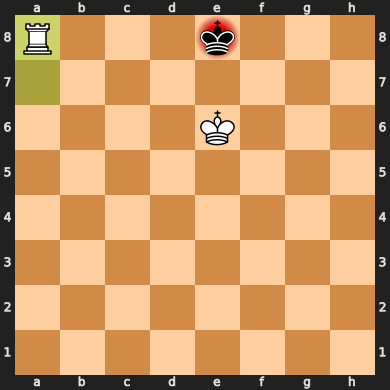

In [ ]:
env = KRKEnv()
env.reset()
env.board = chess.Board("4k3/R7/4K3/8/8/8/8/8 w - - 0 1")   # 直接指定局面

state, reward, done = env.step(chess.Move.from_uci("a7a8"))
print("分數：", reward, " 結束了嗎：", done)   # 應該是 1.0 和 True
env.board

上面那串 `"4k3/R7/..."` 叫做 FEN，是記錄棋盤局面的一種寫法。你不用背，知道它可以描述一個局面就好。

## 5. 讓電腦亂下

### 練習 4：亂下一盤

開一盤新棋，然後一直讓白方隨機走，直到這盤結束。

走了 20 步，最後一步的分數是 -1.0


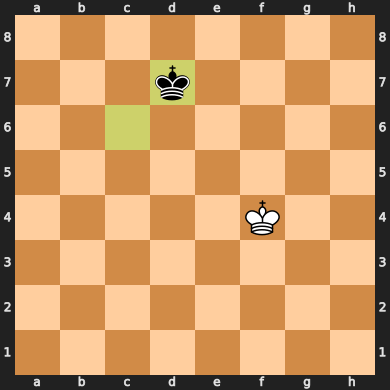

In [ ]:
env = KRKEnv()
state = env.reset()

while not env.is_terminal():
    # TODO: 從 env.legal_actions() 隨機挑一步
    random.choice(env.legal_actions())
    move = random.choice(env.legal_actions())


    state, reward, done = env.step(move)

print("走了", env.steps, "步，最後一步的分數是", reward)
env.board

多跑幾次這一格，看看每次的結果。大部分的時候是怎麼結束的？

### 練習 5：亂下 3000 盤

一盤看不出什麼，我們要跑很多盤來統計。先準備兩個小函式：一個負責下完一盤，一個負責判斷這盤是怎麼結束的。

In [ ]:
def play_random_game(env):
    env.reset()
    while not env.is_terminal():
        move = random.choice(env.legal_actions())
        env.step(move)


def game_result(env):
    if env.board.is_checkmate():
        return "win"
    if env.board.is_stalemate():
        return "stalemate"
    if env.board.is_insufficient_material():
        return "rook lost"
    return "timeout"

接下來換你寫：跑 3000 盤，用一個 dict 記錄每種結果出現幾次，也把每盤走了幾步加起來，最後算平均。

In [ ]:
env = KRKEnv(max_steps=50)
N = 3000

count = {"win": 0, "stalemate": 0, "rook lost": 0, "timeout": 0}
total_steps = 0

for i in range(N):
    play_random_game(env)
    # TODO: 用 game_result(env) 看這盤的結果，在 count 裡對應的數字加 1
    count[game_result(env)] += 1

    # TODO: 把這盤走的步數（env.steps）加到 total_steps
    total_steps += env.steps


for name in count:
    print(name, count[name], "盤，佔", round(count[name] / N * 100, 1), "%")
print("平均每盤走", round(total_steps / N, 1), "步")

win 21 盤，佔 0.7 %
stalemate 7 盤，佔 0.2 %
rook lost 2102 盤，佔 70.1 %
timeout 870 盤，佔 29.0 %
平均每盤走 28.9 步


畫成長條圖比較好看（圖上的字用英文，因為 Colab 預設沒有中文字型）。

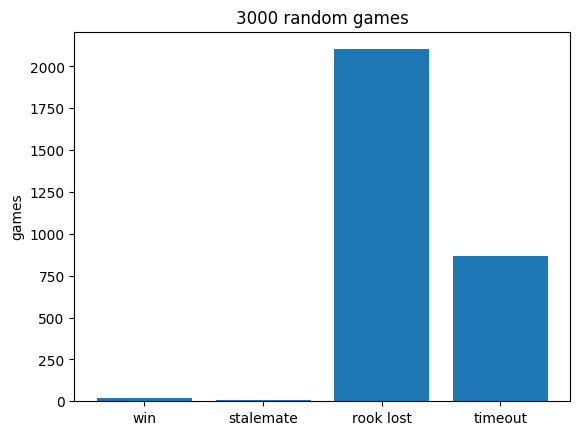

In [ ]:
import matplotlib.pyplot as plt

plt.bar(count.keys(), count.values())
plt.title("3000 random games")
plt.ylabel("games")
plt.show()

把你的勝率寫在這裡，這就是我們的**基準線**。之後電腦學了以後，都要拿來跟這個數字比：

> 亂下 3000 盤，勝率：______ %

## 6. 小測試（回家作業，上課有時間就先做）

寫程式很容易改著改著就把以前寫好的東西弄壞。所以我們寫一些「測試」，每次改完都跑一次，確認還是對的。

`assert 條件` 的意思是：這個條件一定要成立，不成立就馬上報錯。

In [ ]:
def test_checkmate():
    env = KRKEnv()
    env.reset()
    env.board = chess.Board("4k3/R7/4K3/8/8/8/8/8 w - - 0 1")
    state, reward, done = env.step(chess.Move.from_uci("a7a8"))
    assert reward == 1.0
    assert done == True


def test_stalemate():
    # 白車走到 g7 以後，黑王沒被將軍，但也沒有任何一步可以走
    env = KRKEnv()
    env.reset()
    env.board = chess.Board("7k/R7/6K1/8/8/8/8/8 w - - 0 1")
    state, reward, done = env.step(chess.Move.from_uci("a7g7"))
    assert reward == -1.0
    assert done == True


def test_reset():
    env = KRKEnv()
    for i in range(200):
        env.reset()
        assert env.board.is_valid()
        assert env.board.turn == chess.WHITE
        assert len(env.board.piece_map()) == 3


test_checkmate()
test_stalemate()
test_reset()
print("測試全部通過")

## 7. 把成果存到 GitHub

GitHub 可以想成「程式專用的雲端硬碟」，而且它會記住你的每一次存檔。每一次存檔叫做一個 **commit**，就像遊戲的存檔點：之後程式改壞了，可以回到以前任何一個存檔點。

### 第一步：建立一個專案（repository，簡稱 repo）

1. 登入 [github.com](https://github.com)
2. 右上角點「+」→「New repository」
3. Repository name 填 `krk-rl`
4. 選 **Public**
5. 勾選「Add a README file」
6. 按「Create repository」

### 第二步：從 Colab 存進去

1. 回到這個 Colab 筆記本
2. 上方選單「檔案 → 在 GitHub 中儲存副本」（英文介面是 File → Save a copy in GitHub）
3. 第一次會跳出視窗要你登入 GitHub 並按 Authorize（授權），照著做
4. 存放區選 `你的帳號/krk-rl`，分支選 `main`
5. 檔案路徑改成 `lesson01.ipynb`
6. 「修訂版本訊息」（commit message）寫清楚這次做了什麼，例如：`第1堂：完成棋盤環境和亂下3000盤統計`
7. 按確定

### 第三步：回 GitHub 看看

1. 打開 `github.com/你的帳號/krk-rl`，應該看得到 `lesson01.ipynb`，點進去可以直接看到筆記本內容，包含跑出來的棋盤和圖
2. 點檔案列表上方的「commits」（時鐘圖示旁邊），可以看到每一次存檔的紀錄

### 第四步：改 README

README 是專案的說明書，別人打開你的專案第一眼看到的就是它。

1. 在 repo 頁面點 `README.md`，再點右上角的鉛筆圖示
2. 寫幾句話介紹這個專案，例如這個專案在做什麼、今天完成了什麼
3. 按「Commit changes」，訊息寫 `更新README：加入專案介紹`

完成後再看一次 commits，應該有好幾個存檔點了。

### commit 訊息怎麼寫

寫「這次做了什麼」，讓一個月後的你看得懂。

| 不好的寫法 | 好的寫法 |
|---|---|
| update | 加入逼和的測試 |
| aaa | 把最大步數改成可以調整 |
| 改了一些東西 | 修正車被吃掉時沒有結束的問題 |

## 8. 作業

大約 2 到 3 小時。每做完一題，就用「檔案 → 在 GitHub 中儲存副本」存一次，commit 訊息寫清楚做了哪一題。

### 第 1 題：最大步數會影響什麼？

把 `max_steps` 改成 30、50、100，各跑 3000 盤，把結果填進下面的表格（直接雙擊這格就能編輯）：

| 最大步數 | 勝率 | 逼和 | 車被吃 | 時間到 | 平均步數 |
|---|---|---|---|---|---|
| 30 | | | | | |
| 50 | | | | | |
| 100 | | | | | |

看完表格，用自己的話寫兩三句：步數變多，哪些數字跟著變了？為什麼？

### 第 2 題：測試在保護什麼

先執行第 6 段的測試，確認全部通過。接著故意把 `step()` 裡將死的分數從 1.0 改成 0.5，重新執行 class 那格和測試那格，看測試會不會報錯。最後記得改回來。

用一兩句話寫下：如果沒有測試，這種錯誤你會在什麼時候才發現？

（加分，可以不做：寫一個 `test_rook_lost()`，設定一個局面讓黑方唯一能走的就是吃掉白車，檢查分數是 −1。提示：黑王 a8、白車 b7、白王離很遠。）

### 第 3 題：想一想

亂下的時候，最常見的輸法是哪一種？如果你是電腦，要先學會什麼，勝率才會開始變高？寫在下面就好，不用寫程式。

### 挑戰題（可以不做）

寫一個 `smarter_move(env)`：如果有某一步走下去可以直接將死，就走那一步；不然就亂走。用它取代亂走，跑 3000 盤，勝率變多少？

提示：先 `env.board.push(走法)`，用 `is_checkmate()` 檢查，再用 `env.board.pop()` 把那步收回來。

In [ ]:
# 第 1 題寫在這裡

In [ ]:
# 第 2 題寫在這裡

第 3 題寫在這裡：

In [ ]:
# 挑戰題寫在這裡